# Read summary: SEGUL vs fastp and FastQC

Compares `segul read summary` with two widely used read QC tools on the same
gzipped FASTQ files from `data/`:

- **fastp** in report-only mode (`-A -G -Q -L`, no output reads, JSON and HTML
  report).
- **FastQC** restricted to the modules SEGUL Complete also computes, so both
  tools compute the same features.

Results come from `uv run segul2-bench read-summary run` and are read from
`results/read-summary/latest.csv`. Re-run this notebook with:

```bash
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/read_summary.ipynb
```

Two scopes are measured: **file** (each FASTQ file on its own) and
**dataset** (all files of a dataset at once).

In [1]:
import json
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import colormaps
from matplotlib.colors import to_hex
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "read-summary"
FIGURES = ROOT / "figures" / "read-summary"
FIGURES.mkdir(parents=True, exist_ok=True)

runs = pd.read_csv(RESULTS / "latest.csv")
meta = json.loads((RESULTS / "latest.json").read_text())
assert (runs["exit_code"] == 0).all(), "Some runs failed"
THREADS = meta["threads"]

print(f"Date:    {meta['date']}")
print(f"Machine: {meta['machine']['cpu']}, {meta['machine']['logical_cpus']} logical CPUs, "
      f"{meta['machine']['memory_gb']} GB, {meta['machine']['os']}")
print(f"Threads: {THREADS} (segul RAYON_NUM_THREADS, fastp -w, FastQC --threads)")
print(f"Repeats: {meta['repeats']} (+{meta['warmup']} warmup, not recorded)")
print(f"segul:   {meta['segul']['version']} ({meta['segul']['git_rev']}), dup sketch {meta['segul']['dup_size']:,}")
print(f"fastp:   {meta['fastp']['version']}")
print(f"FastQC:  {meta['fastqc']['version']} on {meta['fastqc']['java']}, "
      f"ignored modules: {', '.join(meta['fastqc']['ignored_modules'])}")
for d in meta["datasets"]:
    print(f"Dataset {d['id']}: {d['n_files']} files, {d['size_mb']} MB gz. {d['description']}")

Date:    2026-11-01T11:00:20
Machine: AMD Ryzen 9 5900X 12-Core Processor, 24 logical CPUs, 60.7 GB, Linux 7.0.0-38-generic
Threads: 8 (segul RAYON_NUM_THREADS, fastp -w, FastQC --threads)
Repeats: 3 (+1 warmup, not recorded)
segul:   segul 0.24.0 (24d3a52-dirty), dup sketch 100,000
fastp:   fastp 0.23.4
FastQC:  FastQC v0.13.0 on openjdk version "25.0.4.1" 2026-08-18, ignored modules: tile, kmer
Dataset read-tests: 10 files, 2017.9 MB gz. 5 paired Bunomys samples, reads cleaned by fastp, single-stream gzip (SEGUL read-tests set)
Dataset raw-reads: 6 files, 966.1 MB gz. 3 paired Bunomys samples, raw reads (BGZF compressed)


### What each tool computes

In [2]:
pd.set_option("display.max_colwidth", None)
pd.DataFrame(meta["computes"].items(), columns=["tool and mode", "computes"]).style.hide(axis="index")

tool and mode,computes
segul minimal,Read count only.
segul default,"Read and base counts, length (min/mean/max, N50), GC and N content, base composition, mean/min/max quality, Q20 and Q30 base fractions."
segul complete,"Default plus per-position quality, length/GC/per-read quality distributions, duplication (100,000-sequence sketch), overrepresented sequences, adapter content. Writes CSV files."
fastp report,"Report only (-A -G -Q -L, no -o). Read/base counts, Q20/Q30, GC, per-position quality and base content curves, k-mer counts, insert size (paired). Duplication evaluation off (--dont_eval_duplication). Writes JSON and HTML."
fastqc complete,"Only the modules SEGUL complete also computes: basic statistics, per-base quality (mean and quartiles), per-sequence quality, per-base sequence content, per-sequence GC with theoretical curve, per-base N content, length distribution, duplication levels (first 100,000 distinct sequences), overrepresented sequences, adapter content. Per-tile quality and k-mer content ignored. Writes HTML and a zip of text reports."
fastp complete,"Same as fastp report plus duplication evaluation (default accuracy 1) and overrepresented sequence analysis (-p, every 20th read). No adapter detection because trimming is off (-A)."


In [3]:
# ColorBrewer Dark2, one fixed color per tool. Markers and line styles mark the
# mode, so identity never relies on color alone.
DARK2 = [to_hex(c) for c in colormaps["Dark2"].colors]
TOOL_COLOR = {"segul": DARK2[0], "fastp": DARK2[1], "fastqc": DARK2[2]}
TOOL_NAME = {"segul": "SEGUL", "fastp": "fastp", "fastqc": "FastQC"}
LEVEL = {
    ("segul", "minimal"): "Minimal",
    ("segul", "default"): "Default",
    ("fastp", "report"): "Default",
    ("segul", "complete"): "Complete",
    ("fastp", "complete"): "Complete",
    ("fastqc", "complete"): "Complete",
}
LEVELS = ["Minimal", "Default", "Complete"]
LEVEL_MARKER = {"Minimal": "s", "Default": "o", "Complete": "D"}
LEVEL_LINE = {"Minimal": ":", "Default": "-", "Complete": "--"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
PLAIN = FuncFormatter(lambda v, _: f"{v:g}")

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

runs["level"] = [LEVEL[(t, m)] for t, m in zip(runs["tool"], runs["mode"])]
stats = (
    runs.groupby(["dataset", "scope", "input", "input_mb", "n_files", "tool", "mode", "level", "threads"],
                 as_index=False)
    .agg(wall_s=("wall_s", "median"), wall_min=("wall_s", "min"), wall_max=("wall_s", "max"),
         rss_mb=("max_rss_mb", "median"), rss_min=("max_rss_mb", "min"), rss_max=("max_rss_mb", "max"),
         cpu_s=("user_s", "median"), reads=("reads", "max"))
)

### Every tool reads every record

Read counts from SEGUL Default output (last run) against the counts in fastp's
JSON report and FastQC's `fastqc_data.txt`, per file.

In [4]:
segul_counts = {}
for csv_path in (RESULTS / "work").glob("*/file/*/segul-default/out/*.csv"):
    for _, row in pd.read_csv(csv_path).iterrows():
        segul_counts[row["file_name"].removesuffix(".fq.gz")] = row["read_count"]
files = stats[(stats["scope"] == "file") & stats["tool"].isin(["fastp", "fastqc"])]
check = files[files["mode"].isin(["report", "complete"])].pivot_table(
    index=["dataset", "input"], columns="tool", values="reads", aggfunc="max").astype(int)
check.columns = [f"{c} reads" for c in check.columns]
check["segul reads"] = check.index.get_level_values("input").map(segul_counts)
check["match"] = (check["fastp reads"] == check["segul reads"]) & (check["fastqc reads"] == check["segul reads"])
assert check["match"].all(), "Read counts differ"
check

fastp reads  \
dataset    input                                                         
raw-reads  Bunomys_andrewsi_HH718_Latimojong_READ1             2337013   
           Bunomys_andrewsi_HH718_Latimojong_READ2             2337013   
           Bunomys_chrysocomus_LSUMZ38237_Buliohuto_READ1      2990302   
           Bunomys_chrysocomus_LSUMZ38237_Buliohuto_READ2      2990302   
           Bunomys_chrysocomus_LSUMZ39559_Katopasa_READ1         81029   
           Bunomys_chrysocomus_LSUMZ39559_Katopasa_READ2         81029   
read-tests Bunomys_andrewsi_FMNH218834_SaluTiwo_R1             2223168   
           Bunomys_andrewsi_FMNH218834_SaluTiwo_R2             2223168   
           Bunomys_andrewsi_FMNH218848_Gandangdewata_R1        1543016   
           Bunomys_andrewsi_FMNH218848_Gandangdewata_R2        1543016   
           Bunomys_andrewsi_FMNH218855_SaluTiwo_R1             1682224   
           Bunomys_andrewsi_FMNH218855_SaluTiwo_R2             1682224   
           Bunomys_andrewsi_FMNH219001_SaluTiwo_R1             2136004   
           Bunomys_andrewsi_FMNH219001_SaluTiwo_R2             2136004   
           Bunomys_andrewsi_LSUMZ39561_Katopasa_R1             4394289   
           Bunomys_andrewsi_LSUMZ39561_Katopasa_R2             4394289   

                                                           fastqc reads  \
dataset    input                                                          
raw-reads  Bunomys_andrewsi_HH718_Latimojong_READ1              2337013   
           Bunomys_andrewsi_HH718_Latimojong_READ2              2337013   
           Bunomys_chrysocomus_LSUMZ38237_Buliohuto_READ1       2990302   
           Bunomys_chrysocomus_LSUMZ38237_Buliohuto_READ2       2990302   
           Bunomys_chrysocomus_LSUMZ39559_Katopasa_READ1          81029   
           Bunomys_chrysocomus_LSUMZ39559_Katopasa_READ2          81029   
read-tests Bunomys_andrewsi_FMNH218834_SaluTiwo_R1              2223168   
           Bunomys_andrewsi_FMNH218834_SaluTiwo_R2              2223168   
           Bunomys_andrewsi_FMNH218848_Gandangdewata_R1         1543016   
           Bunomys_andrewsi_FMNH218848_Gandangdewata_R2         1543016   
           Bunomys_andrewsi_FMNH218855_SaluTiwo_R1              1682224   
           Bunomys_andrewsi_FMNH218855_SaluTiwo_R2              1682224   
           Bunomys_andrewsi_FMNH219001_SaluTiwo_R1              2136004   
           Bunomys_andrewsi_FMNH219001_SaluTiwo_R2              2136004   
           Bunomys_andrewsi_LSUMZ39561_Katopasa_R1              4394289   
           Bunomys_andrewsi_LSUMZ39561_Katopasa_R2              4394289   

                                                           segul reads  match  
dataset    input                                                               
raw-reads  Bunomys_andrewsi_HH718_Latimojong_READ1             2337013   True  
           Bunomys_andrewsi_HH718_Latimojong_READ2             2337013   True  
           Bunomys_chrysocomus_LSUMZ38237_Buliohuto_READ1      2990302   True  
           Bunomys_chrysocomus_LSUMZ38237_Buliohuto_READ2      2990302   True  
           Bunomys_chrysocomus_LSUMZ39559_Katopasa_READ1         81029   True  
           Bunomys_chrysocomus_LSUMZ39559_Katopasa_READ2         81029   True  
read-tests Bunomys_andrewsi_FMNH218834_SaluTiwo_R1             2223168   True  
           Bunomys_andrewsi_FMNH218834_SaluTiwo_R2             2223168   True  
           Bunomys_andrewsi_FMNH218848_Gandangdewata_R1        1543016   True  
           Bunomys_andrewsi_FMNH218848_Gandangdewata_R2        1543016   True  
           Bunomys_andrewsi_FMNH218855_SaluTiwo_R1             1682224   True  
           Bunomys_andrewsi_FMNH218855_SaluTiwo_R2             1682224   True  
           Bunomys_andrewsi_FMNH219001_SaluTiwo_R1             2136004   True  
           Bunomys_andrewsi_FMNH219001_SaluTiwo_R2             2136004   True  
           Bunomys_andrewsi_LSUMZ39561_Katopasa_R1             4394289   True  
           Buno

In [5]:
def dataset_bars(data, tools, levels, metric, lo, hi, ylabel, title, fname, fmt):
    datasets = list(data["dataset"].unique())
    fig, axes = plt.subplots(1, len(datasets), figsize=(max(3.2, 1.75 * len(levels)) * len(datasets), 3.8),
                             squeeze=False)
    width = 0.8 / len(tools)
    for ax, ds in zip(axes[0], datasets):
        sub = data[data["dataset"] == ds]
        for i, tool in enumerate(tools):
            for x, level in enumerate(levels):
                row = sub[(sub["tool"] == tool) & (sub["level"] == level)]
                if row.empty:
                    continue
                r = row.iloc[0]
                pos = x + (i - (len(tools) - 1) / 2) * width
                ax.bar(pos, r[metric], width - 0.03, color=TOOL_COLOR[tool], label=TOOL_NAME[tool])
                ax.errorbar(pos, r[metric], yerr=[[r[metric] - r[lo]], [r[hi] - r[metric]]],
                            color=INK, linewidth=1, capsize=0)
                ax.annotate(fmt.format(r[metric]), (pos, r[hi]), xytext=(0, 3),
                            textcoords="offset points", ha="center", fontsize=8, color=INK)
        ax.set_title(f"{ds} ({sub['n_files'].iloc[0]} files, {sub['input_mb'].iloc[0] / 1000:.2f} GB gz)",
                     fontsize=10)
        ax.set_xticks(range(len(levels)), levels)
        ax.set_ylabel(ylabel)
        ax.margins(y=0.12)
        ax.grid(axis="x", visible=False)
    handles, labels = axes[0][0].get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    axes[0][0].legend(unique.values(), unique.keys(), loc="upper left")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(FIGURES / fname, bbox_inches="tight")
    plt.show()


def file_scaling(data, metric, ylabel, title, fname, label):
    datasets = list(data["dataset"].unique())
    fig, axes = plt.subplots(1, len(datasets), figsize=(5.4 * len(datasets), 4.2),
                             squeeze=False, sharey=True)
    for ax, ds in zip(axes[0], datasets):
        for keys, sub in data[data["dataset"] == ds].groupby(["tool", "mode", "level", "threads"]):
            tool, mode, level, threads = keys
            sub = sub.sort_values("input_mb")
            ax.plot(sub["input_mb"], sub[metric], color=TOOL_COLOR[tool], linestyle=LEVEL_LINE[level],
                    linewidth=2, marker=LEVEL_MARKER[level], markersize=6,
                    markeredgecolor="white", markeredgewidth=1, label=label(tool, mode, threads))
        ax.set_title(ds, fontsize=10)
        ax.set_xlabel("Gzipped FASTQ size (MB)")
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(PLAIN)
    axes[0][0].set_ylabel(ylabel)
    handles, labels = axes[0][0].get_legend_handles_labels()
    order = sorted(range(len(labels)), key=lambda i: (not labels[i].startswith("SEGUL"), labels[i]))
    fig.legend([handles[i] for i in order], [labels[i] for i in order], ncol=5, fontsize=9,
               loc="lower center", bbox_to_anchor=(0.5, -0.06))
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(FIGURES / fname, bbox_inches="tight")
    plt.show()


def ratios(data, other):
    wide = data.pivot_table(index=["dataset", "input", "level"], columns="tool",
                            values=["wall_s", "rss_mb", "cpu_s"]).dropna()
    name = TOOL_NAME[other]
    out = pd.DataFrame({
        "SEGUL time (s)": wide[("wall_s", "segul")],
        f"{name} time (s)": wide[("wall_s", other)],
        f"speedup ({name} / SEGUL)": wide[("wall_s", other)] / wide[("wall_s", "segul")],
        "SEGUL CPU (s)": wide[("cpu_s", "segul")],
        f"{name} CPU (s)": wide[("cpu_s", other)],
        "SEGUL peak MB": wide[("rss_mb", "segul")],
        f"{name} peak MB": wide[("rss_mb", other)],
        f"memory ratio ({name} / SEGUL)": wide[("rss_mb", other)] / wide[("rss_mb", "segul")],
    })
    return out.round(2)


def ratio_summary(data, other):
    name = TOOL_NAME[other]
    per_file = ratios(data, other).reset_index()
    cols = [f"speedup ({name} / SEGUL)", f"memory ratio ({name} / SEGUL)"]
    return per_file.groupby(["dataset", "level"])[cols].agg(["median", "min", "max"]).round(1)

## Part 1: SEGUL vs fastp

| Level | SEGUL | fastp |
|---|---|---|
| Minimal | `--mode minimal` | (none: fastp has no count-only mode) |
| Default | `--mode default` | `-A -G -Q -L --dont_eval_duplication` |
| Complete | `--mode complete` | `-A -G -Q -L -p` (duplication + overrepresentation) |

The feature sets overlap but are not identical (see the table above). Both
tools get the same thread count. In the dataset scope SEGUL summarizes all
files in one call; fastp runs once per R1/R2 pair in paired-end mode, one
pair after another (times summed, peak memory = largest pair).

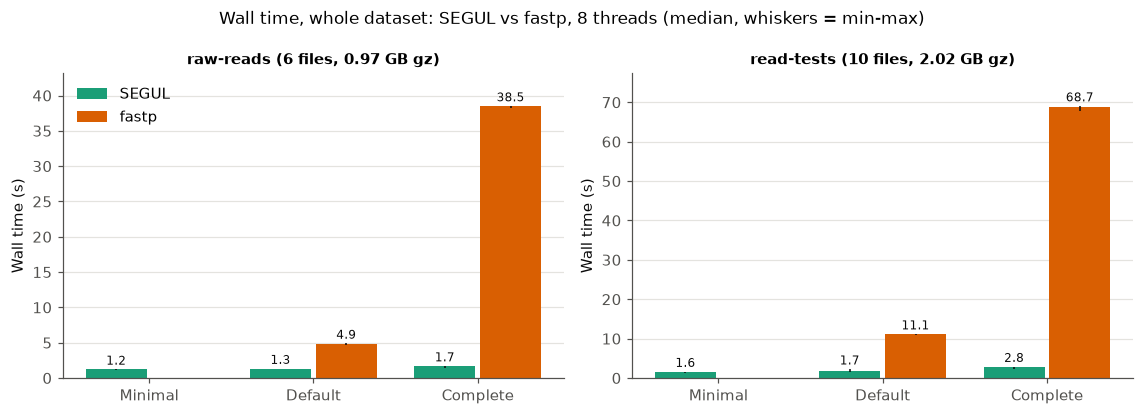

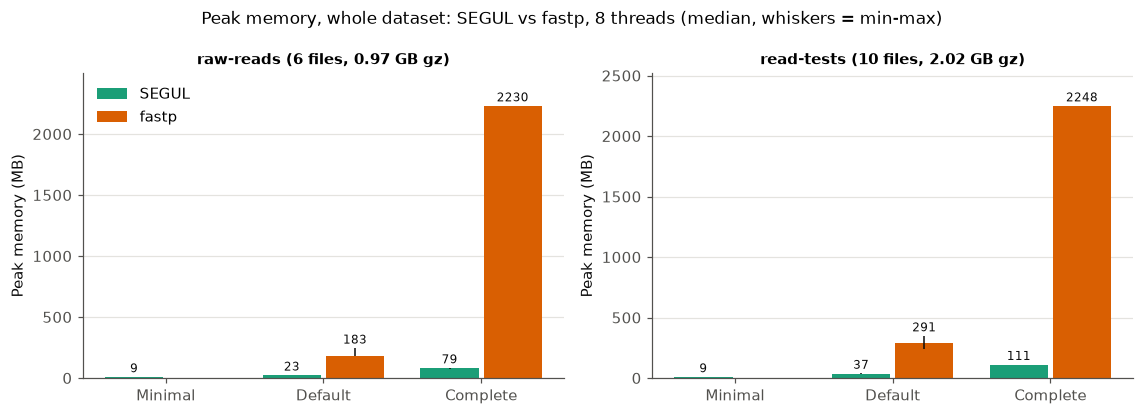

In [6]:
vs_fastp = stats[stats["tool"].isin(["segul", "fastp"]) & (stats["threads"] == THREADS)]
ds = vs_fastp[vs_fastp["scope"] == "dataset"]
note = f"{THREADS} threads (median, whiskers = min-max)"
dataset_bars(ds, ["segul", "fastp"], LEVELS, "wall_s", "wall_min", "wall_max", "Wall time (s)",
             f"Wall time, whole dataset: SEGUL vs fastp, {note}", "fastp-dataset-time.png", "{:.1f}")
dataset_bars(ds, ["segul", "fastp"], LEVELS, "rss_mb", "rss_min", "rss_max", "Peak memory (MB)",
             f"Peak memory, whole dataset: SEGUL vs fastp, {note}", "fastp-dataset-memory.png", "{:.0f}")

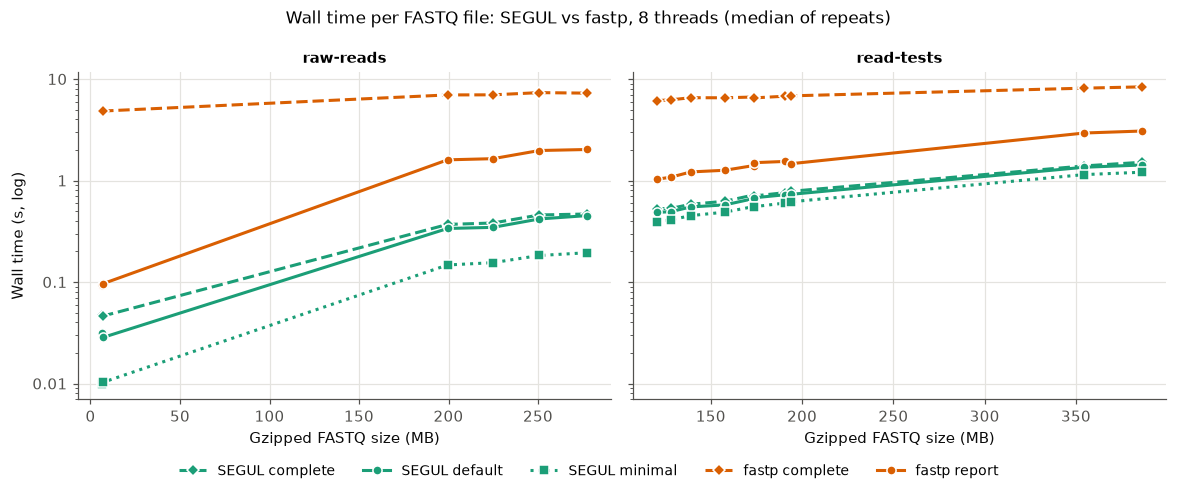

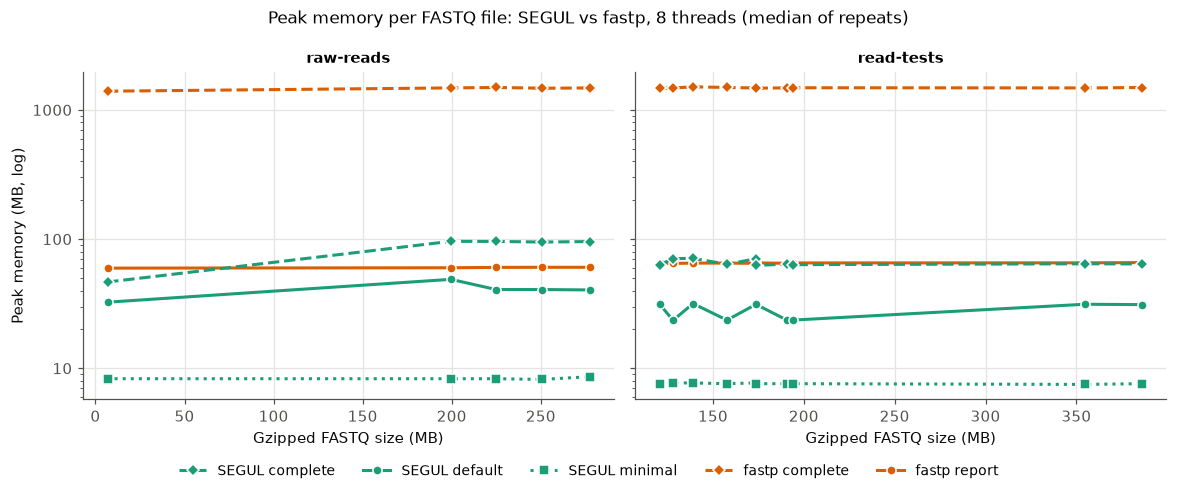

In [7]:
fp_files = vs_fastp[vs_fastp["scope"] == "file"]
fp_label = lambda tool, mode, threads: f"{TOOL_NAME[tool]} {mode}"
file_scaling(fp_files, "wall_s", "Wall time (s, log)",
             f"Wall time per FASTQ file: SEGUL vs fastp, {THREADS} threads (median of repeats)",
             "fastp-file-time.png", fp_label)
file_scaling(fp_files, "rss_mb", "Peak memory (MB, log)",
             f"Peak memory per FASTQ file: SEGUL vs fastp, {THREADS} threads (median of repeats)",
             "fastp-file-memory.png", fp_label)

In [8]:
ratios(ds, 'fastp')

SEGUL time (s)  fastp time (s)  \
dataset    input      level                                      
raw-reads  raw-reads  Complete            1.66           38.52   
                      Default             1.34            4.88   
read-tests read-tests Complete            2.82           68.73   
                      Default             1.67           11.12   

                                speedup (fastp / SEGUL)  SEGUL CPU (s)  \
dataset    input      level                                              
raw-reads  raw-reads  Complete                    23.27          14.19   
                      Default                      3.64           9.30   
read-tests read-tests Complete                    24.39          26.04   
                      Default                      6.66          15.45   

                                fastp CPU (s)  SEGUL peak MB  fastp peak MB  \
dataset    input      level                                                   
raw-reads  raw-reads  Complete          99.89           79.1         2229.9   
                      Default           29.98           23.0          183.3   
read-tests read-tests Complete         189.07          111.2         2247.6   
                      Default           68.09           37.3          291.1   

                                memory ratio (fastp / SEGUL)  
dataset    input      level                                   
raw-reads  raw-reads  Complete                         28.19  
                      Default                           7.97  
read-tests read-tests Complete                         20.21  
                      Default                           7.80

In [9]:
ratio_summary(fp_files, 'fastp')

speedup (fastp / SEGUL)               \
                                     median   min    max   
dataset    level                                           
raw-reads  Complete                    18.6  15.5  104.5   
           Default                      4.6   3.0    4.8   
read-tests Complete                     9.2   5.5   11.8   
           Default                      2.2   2.0    2.2   

                    memory ratio (fastp / SEGUL)              
                                          median   min   max  
dataset    level                                              
raw-reads  Complete                         15.5  15.4  30.0  
           Default                           1.5   1.2   1.8  
read-tests Complete                         23.2  21.0  23.5  
           Default                           2.1   2.1   2.8

## Part 2: SEGUL vs FastQC (identical features)

FastQC runs only the modules SEGUL Complete also computes. Per-tile quality
and k-mer content, which SEGUL does not compute, are set to `ignore` in a
FastQC limits file built from FastQC's defaults. Both tools then compute:

| Feature | SEGUL Complete | FastQC module |
|---|---|---|
| Read count, length range, %GC, encoding | summary CSV | Basic Statistics |
| Per-position quality (mean, P10, quartiles, P90) | `read-pos-summary` | Per base sequence quality |
| Per-position A/C/G/T proportions | `read-pos-summary` | Per base sequence content |
| Per-position N proportion | `read-pos-summary` | Per base N content |
| Per-read mean quality distribution | `read-qscore.csv` | Per sequence quality scores |
| Per-read GC distribution + theoretical curve | `gc.csv` | Per sequence GC content |
| Length distribution | `length.csv` | Sequence Length Distribution |
| Duplication levels (100,000 distinct sequences tracked) | `duplication.csv` | Sequence Duplication Levels |
| Overrepresented sequences | `overrepresented.csv` | Overrepresented sequences |
| Adapter content (Illumina Universal, Nextera, Small RNA, polyA, polyG) | `adapters.csv` | Adapter Content |

Thread budgets match. FastQC uses at most 4 threads per file, so in the
**file** scope both tools get 4 threads. In the **dataset** scope both get the
full thread count and summarize all files in one call.

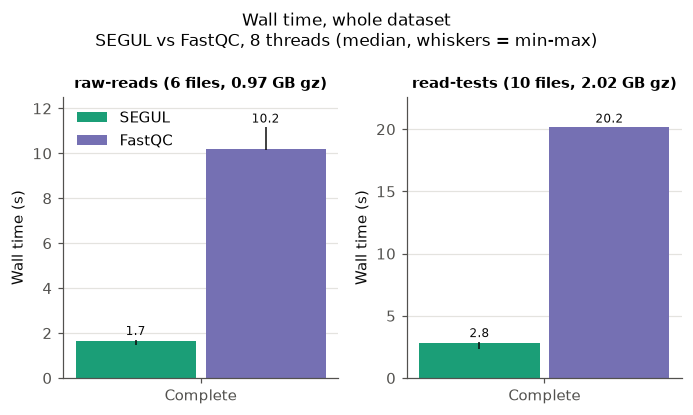

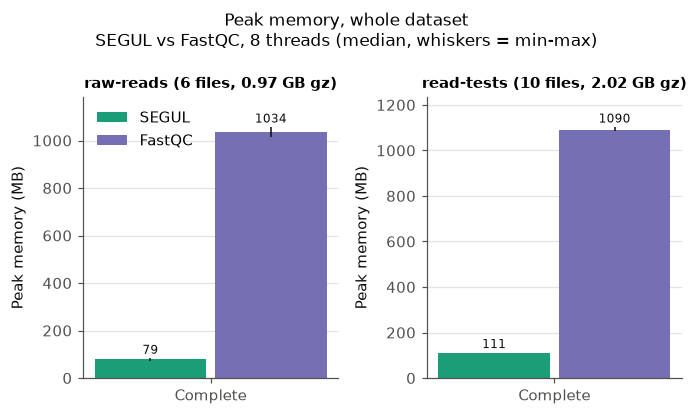

In [10]:
vs_fastqc = stats[(stats["level"] == "Complete") & stats["tool"].isin(["segul", "fastqc"])]
qc_ds = vs_fastqc[(vs_fastqc["scope"] == "dataset") & (vs_fastqc["threads"] == THREADS)]
dataset_bars(qc_ds, ["segul", "fastqc"], ["Complete"], "wall_s", "wall_min", "wall_max", "Wall time (s)",
             f"Wall time, whole dataset\nSEGUL vs FastQC, {note}", "fastqc-dataset-time.png", "{:.1f}")
dataset_bars(qc_ds, ["segul", "fastqc"], ["Complete"], "rss_mb", "rss_min", "rss_max", "Peak memory (MB)",
             f"Peak memory, whole dataset\nSEGUL vs FastQC, {note}", "fastqc-dataset-memory.png", "{:.0f}")

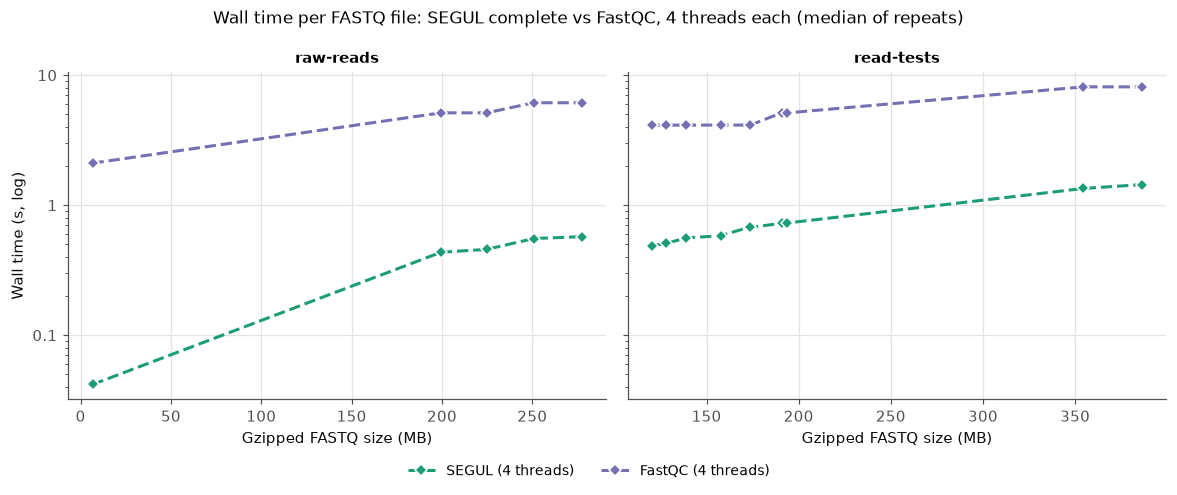

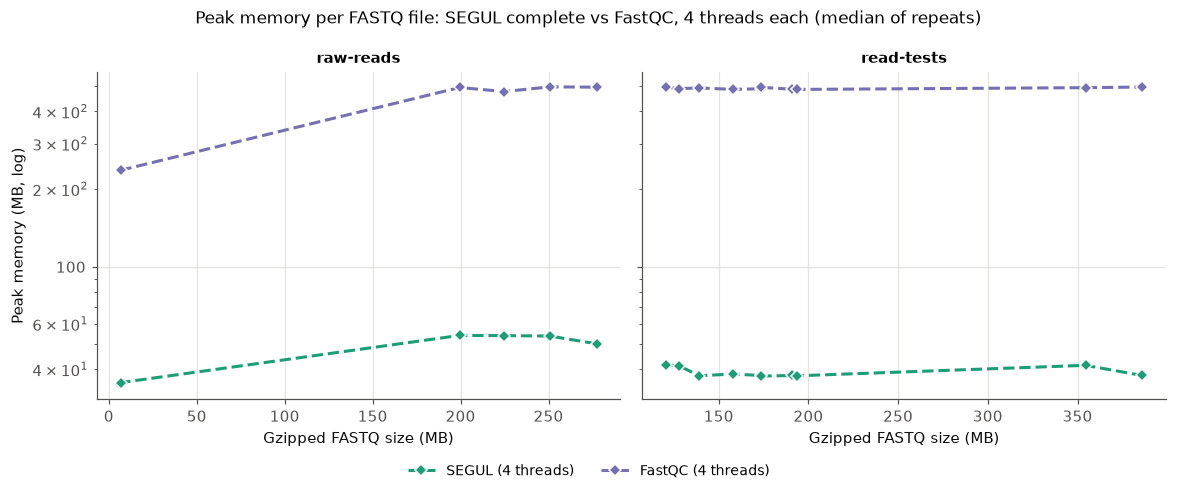

In [11]:
qc_threads = int(vs_fastqc[(vs_fastqc["scope"] == "file") & (vs_fastqc["tool"] == "fastqc")]["threads"].max())
qc_files = vs_fastqc[(vs_fastqc["scope"] == "file") & (vs_fastqc["threads"] == qc_threads)]
qc_label = lambda tool, mode, threads: f"{TOOL_NAME[tool]} ({threads} threads)"
file_scaling(qc_files, "wall_s", "Wall time (s, log)",
             f"Wall time per FASTQ file: SEGUL complete vs FastQC, {qc_threads} threads each (median of repeats)",
             "fastqc-file-time.png", qc_label)
file_scaling(qc_files, "rss_mb", "Peak memory (MB, log)",
             f"Peak memory per FASTQ file: SEGUL complete vs FastQC, {qc_threads} threads each (median of repeats)",
             "fastqc-file-memory.png", qc_label)

In [12]:
ratios(qc_ds, 'fastqc')

,,,SEGUL time (s),FastQC time (s),speedup (FastQC / SEGUL),SEGUL CPU (s),FastQC CPU (s),SEGUL peak MB,FastQC peak MB,memory ratio (FastQC / SEGUL)
dataset,input,level,,,,,,,,
raw-reads,raw-reads,Complete,1.66,10.18,6.15,14.19,55.35,79.1,1033.9,13.07
read-tests,read-tests,Complete,2.82,20.16,7.16,26.04,113.85,111.2,1089.8,9.80


In [13]:
ratio_summary(qc_files, 'fastqc')

speedup (FastQC / SEGUL)              \
                                      median   min   max   
dataset    level                                           
raw-reads  Complete                     11.5  10.7  50.4   
read-tests Complete                      7.0   5.6   8.4   

                    memory ratio (FastQC / SEGUL)              
                                           median   min   max  
dataset    level                                               
raw-reads  Complete                           9.0   6.7   9.9  
read-tests Complete                          12.9  11.9  13.2

### Do the shared features agree?

Basic statistics and duplication from the last run of each tool, per file.
FastQC reports the percentage of reads left after deduplication; SEGUL
reports the estimated duplicate percentage, so the two should add to about
100.

In [14]:
rows = []
for zpath in sorted((RESULTS / "work").glob("*/file/*/fastqc-complete/*_fastqc.zip")):
    with zipfile.ZipFile(zpath) as z:
        text = z.read(f"{zpath.stem}/fastqc_data.txt").decode()
    fq = {}
    for line in text.splitlines():
        parts = line.split("\t")
        if len(parts) >= 2 and parts[0] in ("Total Sequences", "%GC", "Sequence length"):
            fq[parts[0]] = parts[1]
        if line.startswith("#Total Deduplicated Percentage"):
            fq["dedup"] = float(parts[1])
    segul_csv = next(zpath.parent.parent.glob("segul-complete/out/*-read-summary.csv"))
    s = pd.read_csv(segul_csv).iloc[0]
    rows.append({
        "dataset": zpath.parts[-5], "input": zpath.parts[-3],
        "FastQC reads": int(fq["Total Sequences"]), "SEGUL reads": int(s["read_count"]),
        "FastQC %GC": int(fq["%GC"]), "SEGUL %GC": round(100 * s["GC_content"], 1),
        "FastQC length": fq["Sequence length"], "SEGUL length": f"{s['min_read_length']}-{s['max_read_length']}",
        "FastQC dedup %": round(fq["dedup"], 1), "SEGUL duplicate %": round(s["duplicate_pct_est"], 1),
    })
agree = pd.DataFrame(rows)
agree["dedup + duplicate"] = (agree["FastQC dedup %"] + agree["SEGUL duplicate %"]).round(1)
agree

,dataset,input,FastQC reads,SEGUL reads,FastQC %GC,SEGUL %GC,FastQC length,SEGUL length,FastQC dedup %,SEGUL duplicate %,dedup + duplicate
0,raw-reads,Bunomys_andrewsi_HH718_Latimojong_READ1,2337013,2337013,43,43.4,150,150-150,37.3,51.9,89.2
1,raw-reads,Bunomys_andrewsi_HH718_Latimojong_READ2,2337013,2337013,43,43.6,150,150-150,46.0,39.7,85.7
2,raw-reads,Bunomys_chrysocomus_LSUMZ38237_Buliohuto_READ1,2990302,2990302,43,43.4,150,150-150,19.9,68.4,88.3
3,raw-reads,Bunomys_chrysocomus_LSUMZ38237_Buliohuto_READ2,2990302,2990302,43,43.7,150,150-150,26.7,57.2,83.9
4,raw-reads,Bunomys_chrysocomus_LSUMZ39559_Katopasa_READ1,81029,81029,49,49.7,150,150-150,12.5,30.9,43.4
5,raw-reads,Bunomys_chrysocomus_LSUMZ39559_Katopasa_READ2,81029,81029,49,49.6,150,150-150,22.1,21.5,43.6
6,read-tests,Bunomys_andrewsi_FMNH218834_SaluTiwo_R1,2223168,2223168,42,42.8,31-150,31-150,52.3,44.2,96.5
7,read-tests,Bunomys_andrewsi_FMNH218834_SaluTiwo_R2,2223168,2223168,42,42.9,31-150,31-150,55.8,34.7,90.5
8,read-tests,Bunomys_andrewsi_FMNH218848_Gandangdewata_R1,1543016,1543016,41,42.0,31-150,31-150,48.1,47.5,95.6
9,read-tests,Bunomys_andrewsi_FMNH218848_Gandangdewata_R2,1543016,1543016,42,42.0,31-150,31-150,51.2,40.2,91.4


### Notes on fairness

- All tools read the same gzipped files from a warm page cache (one
  unrecorded warmup run per command) and get the same thread budget. fastp
  starts a reader and a writer thread beyond `-w`, and FastQC runs on the JVM,
  whose garbage collector and JIT threads are not counted in `--threads`.
- FastQC peak memory includes the JVM heap (`-Xmx` is 512 MB per file processed
  in parallel, set by the FastQC launcher).
- fastp runs with trimming and filtering disabled and writes no reads, but it
  still computes its full report (quality and base content curves, k-mers, and
  insert size for pairs). SEGUL Default computes fewer per-position curves than
  fastp report, so the Default comparison slightly favors SEGUL in work done;
  SEGUL Complete computes more than fastp complete (adapter content, full length
  and GC distributions).
- fastp's duplication evaluation allocates a fixed table (about 1 GB at the
  default accuracy level), which dominates its memory in the Complete level
  regardless of file size. SEGUL estimates duplication with a fixed-size sketch
  (100,000 sequences), the same approach as FastQC.
- The two datasets are compressed differently. `raw-reads` files are BGZF
  (block gzip), which SEGUL decompresses in parallel, so it reads them faster
  per MB. `read-tests` files were written by fastp as one gzip stream, which
  must be decompressed serially; that is the bottleneck for SEGUL there, and
  why Minimal is barely faster than Default on that dataset.